# Regional gene expression in the adult human brain (Allen Human Brain Atlas)

This notebook asks a simple question: **where in the brain are three disease- and memory-related genes most strongly expressed?**

| Gene | Protein | Why it matters |
|---|---|---|
| `BDNF` | Brain-derived neurotrophic factor | Synaptic plasticity and memory; widely studied in depression |
| `APOE` | Apolipoprotein E | Lipid transport in the brain; the ε4 allele is the strongest common genetic risk factor for late-onset Alzheimer's disease |
| `GRIN2A` | GluN2A subunit of the NMDA receptor | Glutamatergic signalling and learning; variants are linked to epilepsy and schizophrenia |

**Data.** Allen Human Brain Atlas microarray data: 6 adult donors, ~3,700 tissue samples, each annotated to a brain structure ([Hawrylycz et al., *Nature* 2012](https://doi.org/10.1038/nature11405)). Accessed through the Allen Institute API with the Allen SDK. No account or download is needed.

**Pipeline.**
1. Query genes, microarray probes and donors with `allensdk`'s `RmaApi`.
2. Download probe-level expression for every sample from every donor.
3. Map each fine-grained structure to one of 17 broad regions using the atlas ontology.
4. Aggregate: probes → gene per sample → region per donor → region across donors.
5. Visualise with a gene × region heatmap and a bar plot, then interpret.

## 0. Setup
Run the next cell once on Google Colab (or any Python ≥ 3.10 environment). See the README for why `allensdk` is installed with `--no-deps`.

In [1]:
# allensdk 2.16.2 pins numpy<1.24 and pandas==1.5.3, which cannot be built on Python 3.12 (Colab's default).
# The REST-query part of the SDK works fine with modern numpy/pandas, so install it without its pinned
# dependencies and add only the packages its import chain actually needs.
import importlib.util, subprocess, sys
if importlib.util.find_spec("allensdk") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "allensdk==2.16.2"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "requests", "requests-toolbelt", "simplejson", "six", "future",
                    "SimpleITK", "xarray", "pynwb"], check=True)

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from allensdk.api.queries.rma_api import RmaApi

API = "https://api.brain-map.org"          # the SDK defaults to plain http; use https explicitly
rma = RmaApi(base_uri=API)

GENES = ["BDNF", "APOE", "GRIN2A"]
DATA_DIR, FIG_DIR = Path("data"), Path("figures")
DATA_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.precision", 2)

## 1. Query genes, probes and donors

In [3]:
quoted = ",".join(f"'{g}'" for g in GENES)
genes = pd.DataFrame(rma.model_query(
    "Gene",
    criteria=f"[acronym$in{quoted}],products[abbreviation$eq'HumanMA']",
    only=["id", "acronym", "name", "entrez_id"]))

probes = pd.DataFrame(rma.model_query(
    "Probe",
    criteria=f"[gene_id$in{','.join(map(str, genes.id))}],products[abbreviation$eq'HumanMA']",
    only=["id", "name", "gene_id"], num_rows="all"))
probes["gene"] = probes.gene_id.map(genes.set_index("id").acronym)

donors = pd.DataFrame(rma.model_query(
    "Donor", criteria="products[abbreviation$eq'HumanMA']", only=["id", "name"]))

display(genes)
print(f"{len(probes)} microarray probes:", probes.groupby("gene").size().to_dict())
print(f"{len(donors)} donors:", ", ".join(donors.name))

,acronym,entrez_id,id,name
0,GRIN2A,2903,2886,"glutamate receptor, ionotropic, N-methyl D-asp..."
1,APOE,348,345,apolipoprotein E
2,BDNF,627,624,brain-derived neurotrophic factor


10 microarray probes: {'APOE': 3, 'BDNF': 2, 'GRIN2A': 5}
6 donors: H0351.2001, H0351.2002, H0351.1009, H0351.1012, H0351.1015, H0351.1016


## 2. Download sample-level expression
The `human_microarray_expression` service returns, for one donor, a log2 expression value for every requested probe in every tissue sample, plus each sample's structure annotation. The service occasionally returns a transient error, so the helper retries. Results are cached to `data/` so re-runs are instant.

In [4]:
def microarray_expression(probe_ids, donor_id, retries=8):
    url = (f"{API}/api/v2/data/query.json?criteria=service::human_microarray_expression"
           f"[probes$in{','.join(map(str, probe_ids))}][donors$eq{donor_id}]")
    for attempt in range(retries):
        msg = rma.json_msg_query(url)
        if isinstance(msg, dict):            # success: {'probes': [...], 'samples': [...]}
            return msg
        time.sleep(2 * (attempt + 1))        # failure: the SDK returns the error string
    raise RuntimeError(f"Query failed after {retries} attempts: {msg}")

cache = DATA_DIR / "expression_long.csv"
if cache.exists():
    long = pd.read_csv(cache)
else:
    frames = []
    for _, d in donors.iterrows():
        res = microarray_expression(probes.id, d.id)
        samples = pd.DataFrame({
            "donor": d["name"],
            "sample_idx": range(len(res["samples"])),
            "structure_id": [s["structure"]["id"] for s in res["samples"]],
            "structure": [s["structure"]["name"] for s in res["samples"]],
        })
        for p in res["probes"]:
            frames.append(samples.assign(probe=p["name"], gene=p["gene-symbol"],
                                         expr=pd.to_numeric(p["expression_level"])))
    long = pd.concat(frames, ignore_index=True)
    long.to_csv(cache, index=False)

n_samples = long.drop_duplicates(["donor", "sample_idx"]).shape[0]
print(f"{len(long):,} probe × sample measurements, {n_samples:,} tissue samples")
long.drop_duplicates(["donor", "sample_idx"]).groupby("donor").size().rename("samples").to_frame().T

37,020 probe × sample measurements, 3,702 tissue samples


donor,H0351.1009,H0351.1012,H0351.1015,H0351.1016,H0351.2001,H0351.2002
samples,363,529,470,501,946,893


### Quality check: do probes for the same gene agree?
Each gene is measured by 2–5 probes. If they are strongly correlated across samples, averaging them into one gene-level value is reasonable.

In [5]:
for gene, sub in long.groupby("gene"):
    wide = sub.pivot_table(index=["donor", "sample_idx"], columns="probe", values="expr")
    r = wide.corr().where(~np.eye(wide.shape[1], dtype=bool)).stack()
    print(f"{gene:7s} {wide.shape[1]} probes, pairwise Pearson r = {r.min():.2f} to {r.max():.2f}")

APOE    3 probes, pairwise Pearson r = 0.65 to 0.91
BDNF    2 probes, pairwise Pearson r = 0.75 to 0.75
GRIN2A  5 probes, pairwise Pearson r = 0.87 to 0.96


## 3. Map structures to broad brain regions
Samples are annotated to fine structures (for example *CA1 field, right*). The atlas ontology gives each structure its full ancestor path, so a sample belongs to a broad region if that region's ID is on its path. White matter, ventricles and a few unlisted nuclei are excluded so the comparison is between gray-matter regions.

In [6]:
ontology = pd.DataFrame(rma.model_query(
    "Structure", criteria="[graph_id$eq10]",          # graph 10 = adult human brain ontology
    only=["id", "acronym", "name", "structure_id_path"], num_rows="all")).set_index("id")

REGIONS = {  # display name: Allen structure ID
    # neocortex
    "Frontal cortex": 4009, "Temporal cortex": 4132, "Parietal cortex": 4084, "Occipital cortex": 4180,
    "Cingulate cortex": 4220, "Insula": 4268,
    # medial temporal lobe / limbic
    "Parahippocampal gyrus": 4242, "Hippocampus": 4249, "Amygdala": 4327,
    # subcortical, brainstem, cerebellum
    "Striatum": 4277, "Globus pallidus": 4293, "Thalamus": 4392,
    "Hypothalamus": 4540, "Midbrain": 9001, "Pons": 9131, "Medulla": 9512, "Cerebellum": 4696,
}
assert all(ontology.loc[i, "name"] for i in REGIONS.values())   # every ID exists in the ontology

def to_region(structure_id):
    path = {int(x) for x in ontology.loc[structure_id, "structure_id_path"].strip("/").split("/")}
    return next((name for name, rid in REGIONS.items() if rid in path), None)

long["region"] = long.structure_id.map({s: to_region(s) for s in long.structure_id.unique()})

per_sample = long.drop_duplicates(["donor", "sample_idx"])
print(f"Excluded (white matter, ventricles, other): {per_sample.region.isna().sum()} of {len(per_sample)} samples")
per_sample.region.value_counts().rename("samples").to_frame().T

Excluded (white matter, ventricles, other): 150 of 3702 samples


region,Frontal cortex,Temporal cortex,Cerebellum,Parietal cortex,Medulla,Occipital cortex,Thalamus,Pons,Hippocampus,Midbrain,Striatum,Cingulate cortex,Hypothalamus,Amygdala,Parahippocampal gyrus,Insula,Globus pallidus
samples,537,470,368,290,279,212,209,189,188,182,170,148,102,67,58,44,39


## 4. Aggregate expression with pandas
Three steps, chosen so no single donor or densely-sampled region dominates:
1. **Gene per sample:** mean of that gene's probes (log2 units).
2. **Region per donor:** mean over that donor's samples in the region.
3. **Region overall:** mean over the 6 donors, with the standard error across donors.

For the heatmap, each gene is also **z-scored within each donor** across samples. Raw log2 values are not comparable *between* genes, because probes differ in hybridisation efficiency, but z-scores show where each gene is relatively high or low.

In [7]:
gm = long.dropna(subset=["region"])
sample_expr = gm.groupby(["donor", "sample_idx", "region", "gene"], as_index=False).expr.mean()
sample_expr["z"] = sample_expr.groupby(["donor", "gene"]).expr.transform(lambda x: (x - x.mean()) / x.std())

donor_region = sample_expr.groupby(["gene", "region", "donor"], as_index=False)[["expr", "z"]].mean()
summary = (donor_region.groupby(["gene", "region"])
           .agg(log2_mean=("expr", "mean"), log2_sem=("expr", "sem"), z_mean=("z", "mean"), donors=("donor", "nunique"))
           .reset_index())
assert (summary.donors == len(donors)).all()     # every region is sampled in every donor
summary.to_csv(DATA_DIR / "region_summary.csv", index=False)

z_matrix = summary.pivot(index="gene", columns="region", values="z_mean").loc[GENES]
z_matrix = z_matrix[list(REGIONS)]        # anatomical order: cortex -> limbic -> subcortical -> hindbrain
z_matrix

region,Frontal cortex,Temporal cortex,Parietal cortex,Occipital cortex,Cingulate cortex,Insula,Parahippocampal gyrus,Hippocampus,Amygdala,Striatum,Globus pallidus,Thalamus,Hypothalamus,Midbrain,Pons,Medulla,Cerebellum
gene,,,,,,,,,,,,,,,,,
BDNF,0.28,0.49,0.23,0.17,0.33,0.59,0.34,0.89,0.12,-2.20,-1.86,-0.96,-0.71,-0.82,-0.40,-0.60,0.82
APOE,-0.47,-0.19,-0.50,-0.78,-0.19,-0.19,0.37,-0.88,0.97,1.30,2.61,0.55,0.96,1.28,0.08,-0.12,-0.03
GRIN2A,0.68,0.67,0.77,0.92,0.57,0.58,0.56,0.87,0.01,-0.47,-0.81,-0.32,-1.86,-1.08,-1.56,-1.19,-0.62


## 5. Heatmap: gene × region

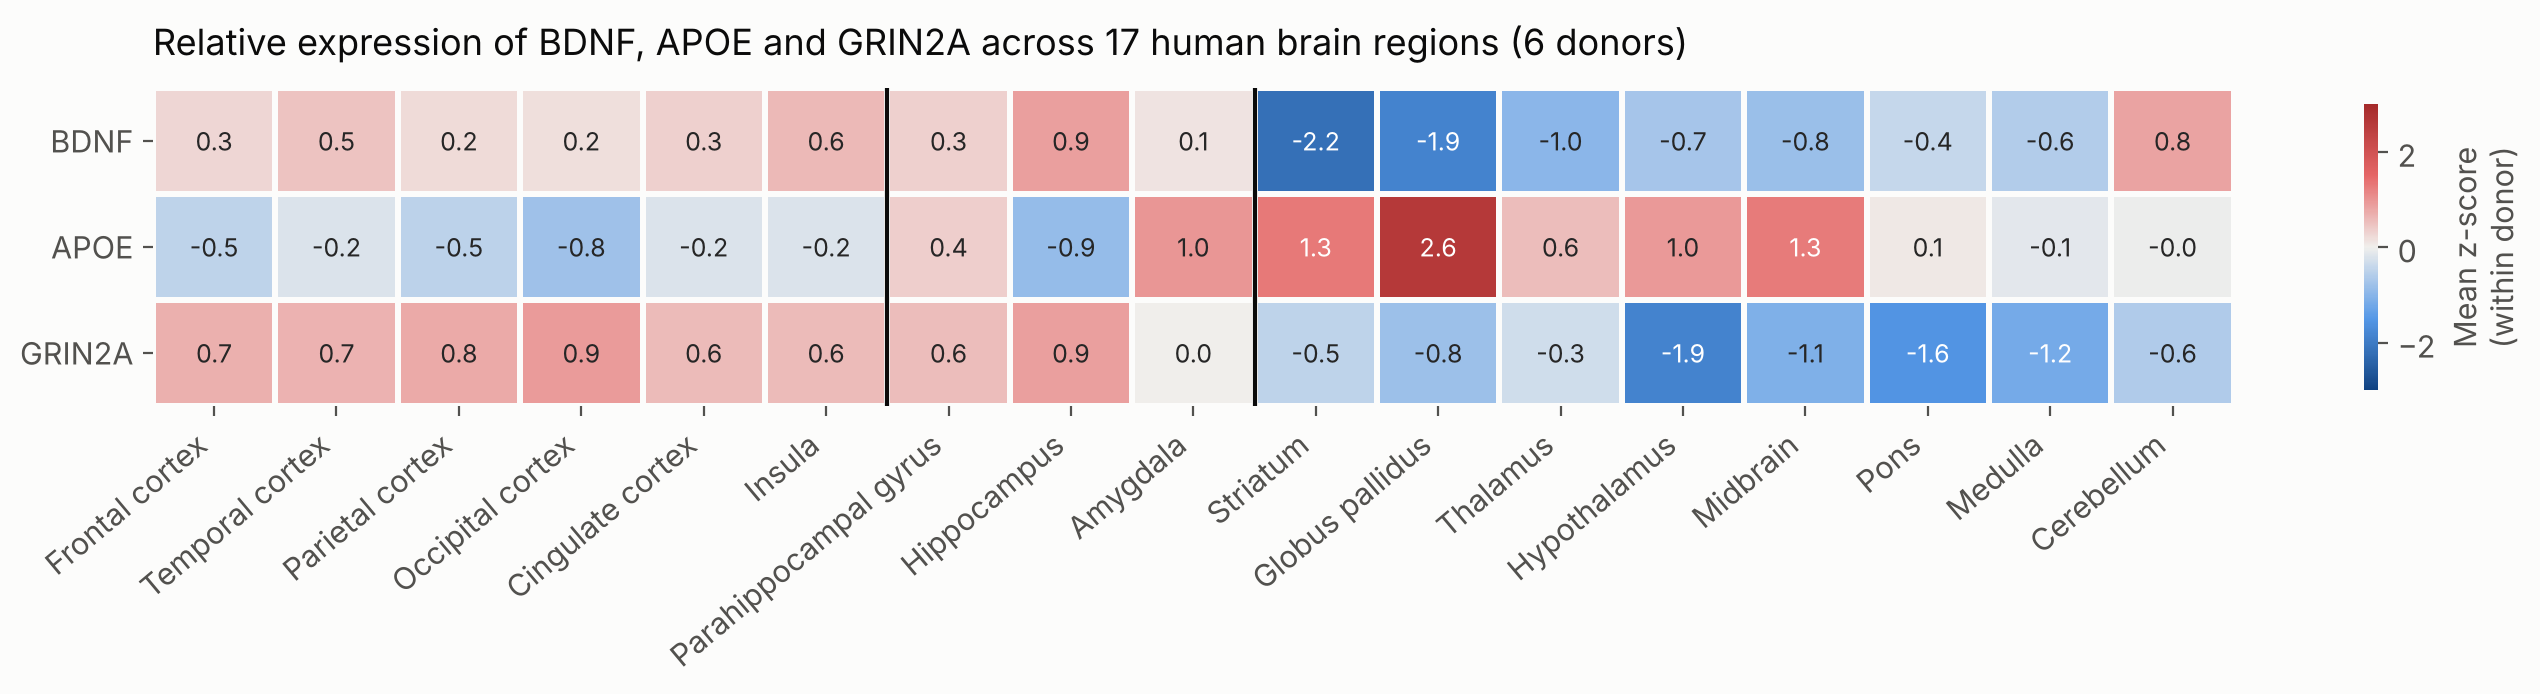

In [8]:
# Vertical separators between anatomical groups are drawn after plotting.
# Diverging map: blue (below the gene's brain-wide mean) -> neutral gray (mean) -> red (above).
div = LinearSegmentedColormap.from_list("div", ["#104281", "#5598e7", "#f0efec", "#e66767", "#a52a2a"])
plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})

fig, ax = plt.subplots(figsize=(14, 3.6))
lim = np.ceil(np.abs(z_matrix.values).max() * 2) / 2
sns.heatmap(z_matrix, cmap=div, center=0, vmin=-lim, vmax=lim, annot=True, fmt=".1f",
            annot_kws={"size": 9}, linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "Mean z-score\n(within donor)", "shrink": 0.9}, ax=ax)
for x in (6, 9):                                    # neocortex | limbic | subcortical & hindbrain
    ax.axvline(x, color="#0b0b0b", linewidth=1.5)
ax.set(xlabel="", ylabel="")
ax.set_title("Relative expression of BDNF, APOE and GRIN2A across 17 human brain regions (6 donors)",
             loc="left", fontsize=13, color="#0b0b0b", pad=12)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right"); plt.setp(ax.get_yticklabels(), rotation=0)
fig.patch.set_facecolor("#fcfcfb")
plt.tight_layout(); fig.savefig(FIG_DIR / "heatmap_gene_by_region.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()

## 6. Bar plot: BDNF across regions
Bars are the mean over donors (log2 expression); dots are individual donors, so the spread across people is visible.

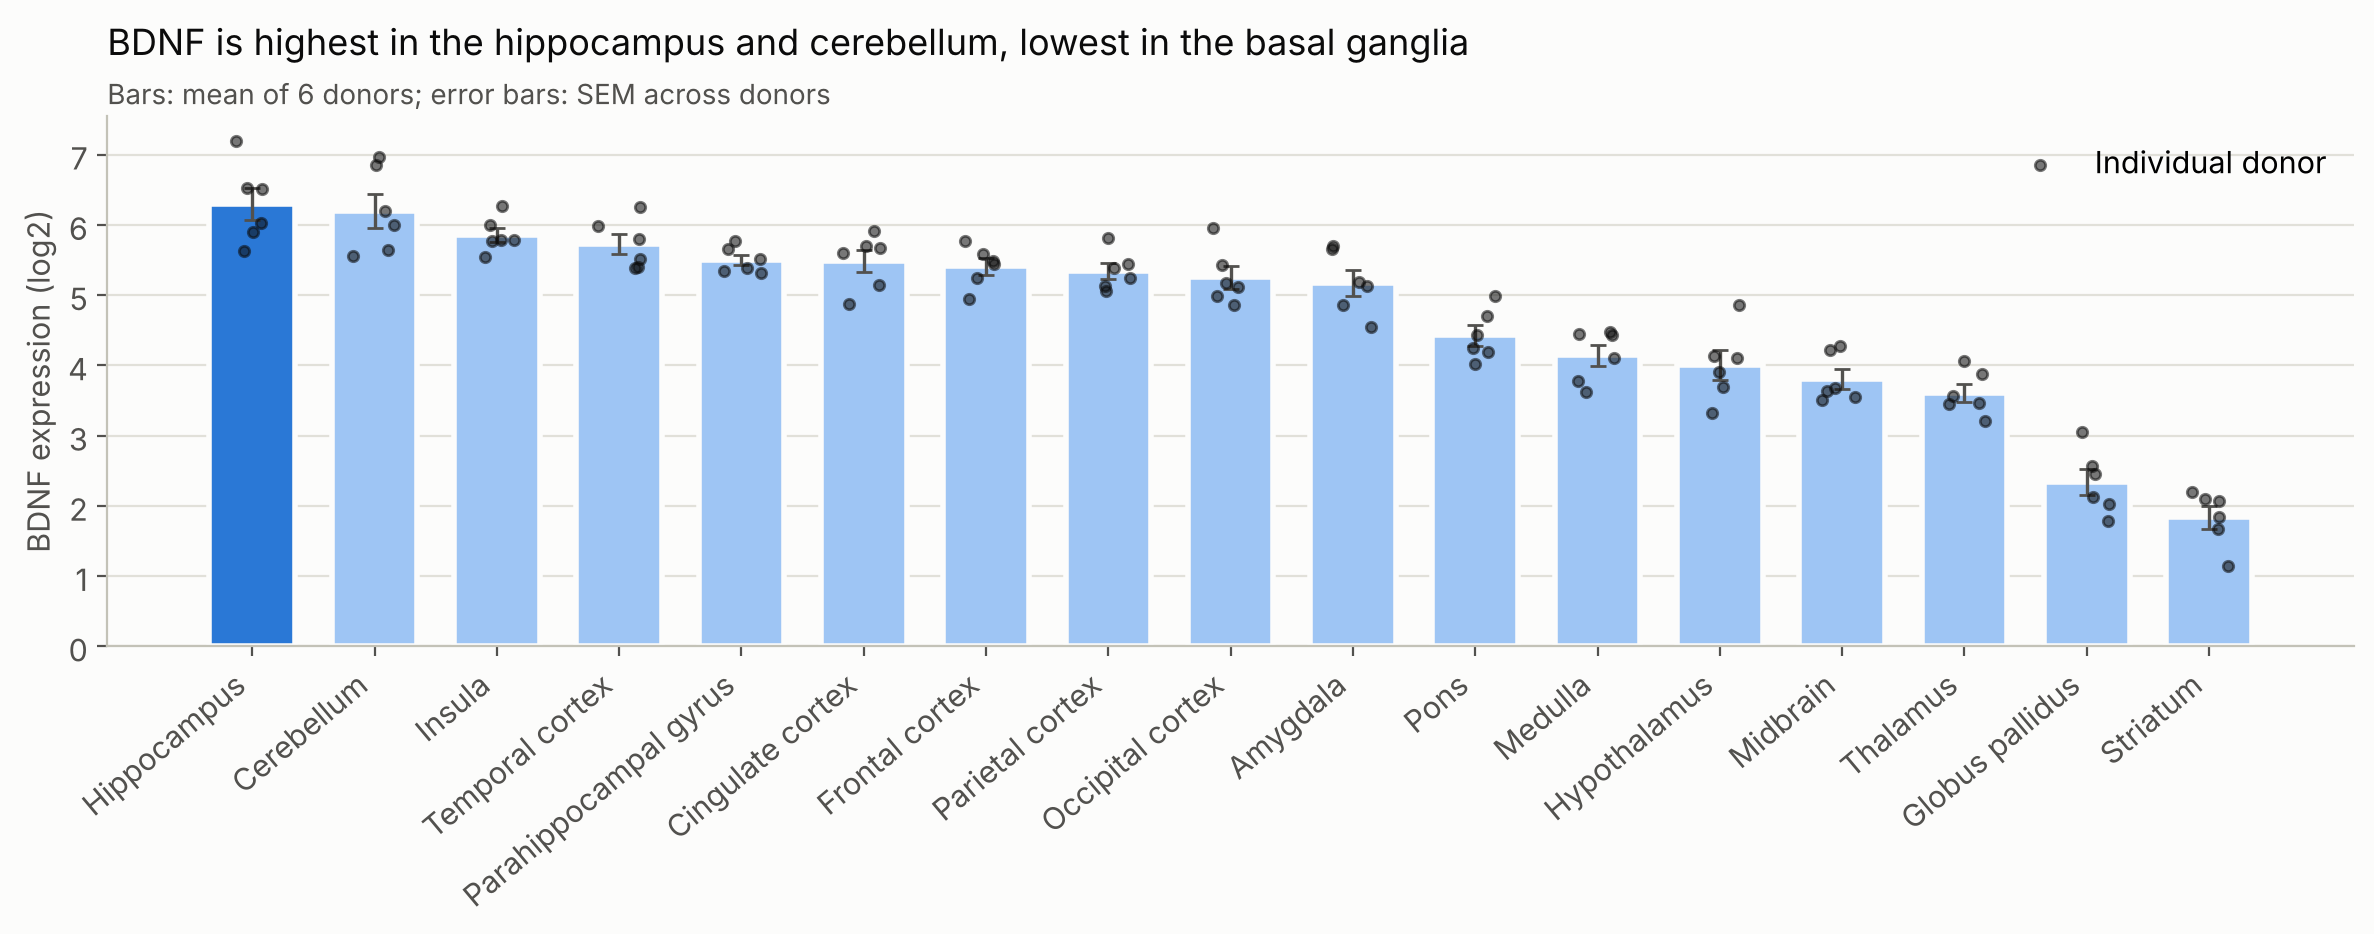

,region,log2_mean,log2_sem
22,Hippocampus,6.30,0.23
18,Cerebellum,6.20,0.24
24,Insula,5.86,0.10
32,Temporal cortex,5.72,0.14
28,Parahippocampal gyrus,5.50,0.08


In [9]:
GENE = "BDNF"
s = summary[summary.gene == GENE].sort_values("log2_mean", ascending=False)
order = s.region.tolist()
top = order[0]

fig, ax = plt.subplots(figsize=(12, 4.8))
colors = ["#2a78d6" if r == top else "#9ec5f4" for r in order]
ax.bar(order, s.log2_mean, color=colors, width=0.7, edgecolor="#fcfcfb", linewidth=2, zorder=2)
ax.errorbar(order, s.log2_mean, yerr=s.log2_sem, fmt="none", ecolor="#52514e", elinewidth=1.2, capsize=3, zorder=3)
pts = donor_region[donor_region.gene == GENE]
x = pts.region.map({r: i for i, r in enumerate(order)})
ax.scatter(x + np.random.default_rng(0).uniform(-0.18, 0.18, len(x)), pts.expr,
           s=14, color="#0b0b0b", alpha=0.55, zorder=4, label="Individual donor")
ax.set_ylabel(f"{GENE} expression (log2)")
ax.text(0, 1.01, "Bars: mean of 6 donors; error bars: SEM across donors", transform=ax.transAxes, color="#52514e", fontsize=10, va="bottom")
ax.set_title(f"{GENE} is highest in the hippocampus and cerebellum, lowest in the basal ganglia",
             loc="left", fontsize=13, color="#0b0b0b", pad=22)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
plt.tight_layout(); fig.savefig(FIG_DIR / "bar_bdnf_by_region.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()
s[["region", "log2_mean", "log2_sem"]].head(5)

## 7. Top region-specific patterns
For each gene: the highest and lowest regions, and a paired test of hippocampus against the mean of the six neocortical regions, across the 6 donors. With n = 6 the test is a sanity check, not strong inference.

In [10]:
NEOCORTEX = ["Frontal cortex", "Temporal cortex", "Parietal cortex", "Occipital cortex", "Cingulate cortex", "Insula"]
rows = []
for g in GENES:
    sg = summary[summary.gene == g].sort_values("log2_mean", ascending=False)
    d = donor_region[donor_region.gene == g].pivot(index="donor", columns="region", values="expr")
    hip, ctx = d["Hippocampus"], d[NEOCORTEX].mean(axis=1)
    t, p = stats.ttest_rel(hip, ctx)
    rows.append({"gene": g,
                 "top 3 regions": ", ".join(sg.region.head(3)),
                 "bottom 3 regions": ", ".join(sg.region.tail(3)),
                 "max-min range (log2)": sg.log2_mean.max() - sg.log2_mean.min(),
                 "hippocampus - neocortex (log2)": (hip - ctx).mean(),
                 "paired t-test p (n=6)": p})
patterns = pd.DataFrame(rows).set_index("gene")
patterns.style.format({"max-min range (log2)": "{:.2f}", "hippocampus - neocortex (log2)": "{:+.2f}",
                       "paired t-test p (n=6)": "{:.3f}"})

,top 3 regions,bottom 3 regions,max-min range (log2),hippocampus - neocortex (log2),paired t-test p (n=6)
gene,,,,,
BDNF,"Hippocampus, Cerebellum, Insula","Thalamus, Globus pallidus, Striatum",4.46,+0.78,0.014
APOE,"Globus pallidus, Midbrain, Striatum","Parietal cortex, Hippocampus, Occipital cortex",2.87,-0.30,0.292
GRIN2A,"Occipital cortex, Hippocampus, Parietal cortex","Medulla, Pons, Hypothalamus",3.58,+0.20,0.075


In [11]:
# Pairwise spatial similarity of the three genes' regional profiles (Spearman, 17 regions)
summary.pivot(index="region", columns="gene", values="log2_mean")[GENES].corr(method="spearman")

gene,BDNF,APOE,GRIN2A
gene,,,
BDNF,1.00,-0.69,0.58
APOE,-0.69,1.00,-0.77
GRIN2A,0.58,-0.77,1.00


## 8. Biological interpretation

**BDNF** is highest in the hippocampus (and, nearly tied, the cerebellum), about 0.8 log2 units (~1.7-fold) above the neocortical average (paired t-test p = 0.014, n = 6). The direction held in all six donors, although in one donor the gap was negligible (0.02 log2). Its expression in the striatum and globus pallidus is ~4.5 log2 units below the hippocampus, which fits the established view that striatal BDNF protein is mostly delivered by cortical inputs rather than made locally. **GRIN2A** follows a similar "forebrain neuron" profile, high across neocortex and hippocampus and low in the hypothalamus and brainstem; its relatively low cerebellar level is consistent with cerebellar granule cells relying on a different NMDA subunit (GluN2C). **APOE** shows the opposite pattern (Spearman ρ = −0.69 with BDNF and −0.77 with GRIN2A across regions), peaking in the globus pallidus, midbrain and striatum and dipping in the hippocampus. Because APOE is made mainly by astrocytes, this probably reflects higher glial content in subcortical gray matter (an inference this bulk data cannot confirm), and it shows that the hippocampus's vulnerability in Alzheimer's disease is not explained by unusually high local *APOE* mRNA.

## Limitations
- **Six donors**, mostly middle-aged adults, with no disease cases. Patterns describe the typical healthy adult brain, not disease.
- **Microarray, bulk tissue.** Each sample mixes many cell types, so a regional difference can reflect cell composition (for example more glia) rather than per-cell expression.
- **Probe averaging.** Gene values average all probes for the gene. The probes agree well here (QC above), but probe choice can matter for other genes.
- **Cross-gene levels are not comparable** in raw log2 units, which is why the heatmap uses within-gene z-scores.
- Four of the six donors were sampled in the left hemisphere only, so hemispheric differences are not analysed.